# Task 1 — Ethereum Transaction Activity

## Analytical question

**How did Ethereum's daily transaction activity change during the 30-day period?**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**

### Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `transactions`
- **SQL query:** `sql/01_network_activity.sql`

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The window contains **31 calendar dates**, but the first and last dates are partial days. For comparable daily statistics, the analysis uses the **29 complete calendar days**.

## Define Transaction Activity

**Transaction activity** refers to the number of transactions recorded on the Ethereum network over a specified period.

In this analysis, transaction activity is measured using **transaction count**, which represents the total number of Ethereum transactions recorded within each calendar day.

> **transaction_count = Number of Ethereum transactions recorded per day**

This metric measures the volume of transactions processed by the network. It does **not** directly measure unique users, active addresses, transaction value, token transfers, or smart contract activity.

In [87]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## 1. Load the analytical dataset

The SQL aggregation was performed in BigQuery rather than loading raw Ethereum transactions into Pandas.

The BigQuery result was exported as:

`data/processed/daily_transactions.csv`

Only the aggregated daily result is brought into Python.

In [88]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/daily_transactions.csv")

df["date"] = pd.to_datetime(df["date"])  # Convert the date column to datetime format

df.head()

,date,transaction_count
0,2026-08-24,"1,157,222"
1,2026-08-25,"1,994,723"
2,2026-08-26,"1,898,276"
3,2026-08-27,"1,931,985"
4,2026-08-28,"1,902,964"


## 3. Validate the analytical dataset

Check:

- number of rows
- column types
- missing values
- duplicate dates
- whether the expected 31 calendar dates are present

Expected structure:

- 31 rows: one row for each calendar date touched by the 30-day timestamp window
- 2 columns: `date` and `transaction_count`
- No missing values
- `date` should be datetime
- `transaction_count` should be numeric

In [89]:
df.shape

(31, 2)

In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               31 non-null     datetime64[ns]
 1   transaction_count  31 non-null     int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 628.0 bytes


In [91]:
# Confirm the date range
df["date"].min(), df["date"].max()


(Timestamp('2026-08-24 00:00:00'), Timestamp('2026-09-23 00:00:00'))

In [92]:
# Check for missing values
df.isna().sum()


date                0
transaction_count   0
dtype: int64

In [93]:
# Check for duplicate dates
df["date"].duplicated().sum()


np.int64(0)

## 3. Identify partial boundary days

Because the analysis window begins and ends at 10:01:35 UTC, August 24 and September 23 are partial calendar days.

They should not be compared directly with the 29 complete days.

In [94]:
# Identify the first and last dates as partial days
df["is_partial_day"] = df["date"].isin([df["date"].min(), df["date"].max()])

# Keep only complete calendar days for comparable daily analysis
complete_days = df[~df["is_partial_day"]]

# Check how many complete and partial days are present
df["is_partial_day"].value_counts()

is_partial_day
False   29
True     2
Name: count, dtype: int64

In [95]:
# Keep only complete calendar days.
# .copy() creates an independent DataFrame that we can safely modify.
complete_days = df[~df["is_partial_day"]].copy()

complete_days.shape

(29, 3)

## 4. Baseline statistics

Use the 29 complete days for comparable daily statistics.

The mean describes the arithmetic average daily transaction count. The median provides a second baseline that is less sensitive to unusually high or low observations.

In [96]:
average_daily_transactions = complete_days["transaction_count"].mean()
median_daily_transactions = complete_days["transaction_count"].median()

average_daily_transactions, median_daily_transactions

(np.float64(1901759.8275862068), np.float64(1917517.0))

## 5. Highest and lowest complete days

In [97]:
highest_day = complete_days.sort_values(by="transaction_count", ascending=False).head(1)  
highest_day

,date,transaction_count,is_partial_day
18,2026-09-11,"2,097,342",False


In [98]:
lowest_day = complete_days.sort_values(by="transaction_count").head(1)     
lowest_day

,date,transaction_count,is_partial_day
20,2026-09-13,"1,476,230",False


In [99]:
highest_daily_transaction = complete_days["transaction_count"].max()
lowest_daily_transaction = complete_days["transaction_count"].min()

Percentage_difference = ((highest_daily_transaction - lowest_daily_transaction) /
                         lowest_daily_transaction) * 100

Percentage_difference

np.float64(42.07420252941615)

## 6. First-to-last complete-day change

This compares the first and last complete days rather than the two partial boundary dates.

In [100]:
first_day = complete_days.head(1)
first_day

,date,transaction_count,is_partial_day
1,2026-08-25,"1,994,723",False


In [101]:
last_day = complete_days.tail(1)
last_day

,date,transaction_count,is_partial_day
29,2026-09-22,"2,094,087",False


In [102]:
percentage_change = ((last_day["transaction_count"].values - 
                      first_day["transaction_count"].values) /
                        first_day["transaction_count"].values) * 100

percentage_change

array([4.98134327])

## 7. Visulize Daily transaction activity

The daily series shows short-term fluctuations in Ethereum transaction activity.

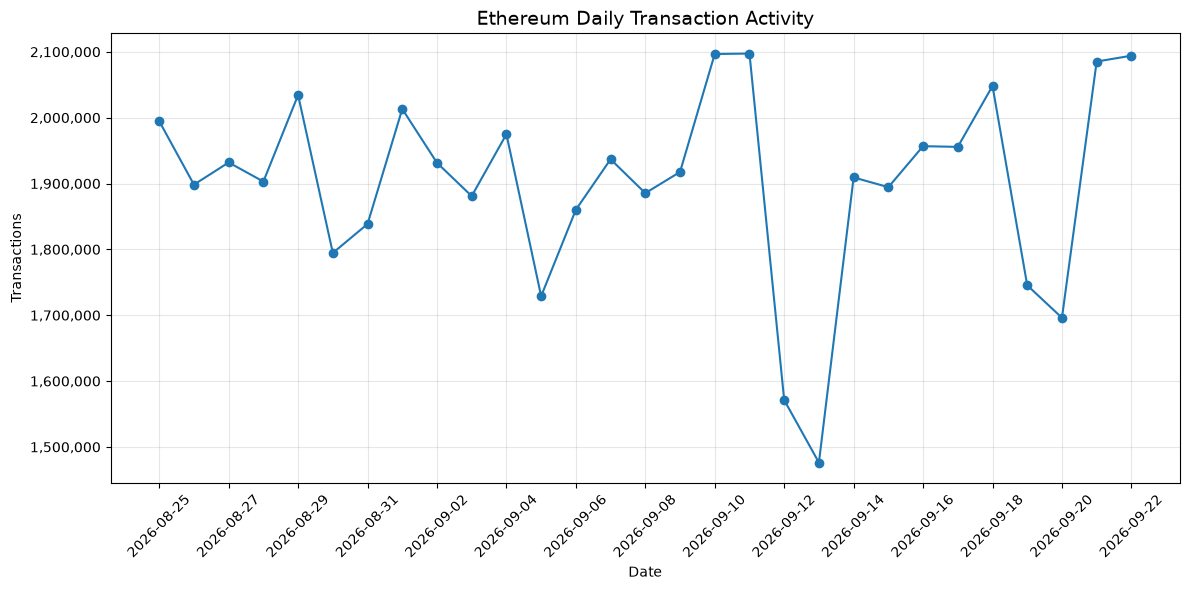

In [103]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    complete_days["date"],
    complete_days["transaction_count"],
    marker="o"
)

plt.title("Ethereum Daily Transaction Activity", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Transactions")

# Format y-axis with commas
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

# Show every 2nd date
ax.set_xticks(complete_days["date"][::2])
ax.tick_params(axis="x", rotation=45)

ax.grid(alpha=0.3)
# ax.grid(axis="y")

plt.tight_layout()
plt.show()

## 8. Seven-day rolling average

A 7-day rolling average smooths individual daily fluctuations and helps reveal the underlying short-term pattern.

In [104]:
complete_days["rolling_7d"] = (
    complete_days["transaction_count"]
    .rolling(window=7)
    .mean()
)

complete_days[["date", "transaction_count", "rolling_7d"]].tail(10)

,date,transaction_count,rolling_7d
20,2026-09-13,"1,476,230","1,854,455.86"
21,2026-09-14,"1,909,218","1,850,511.71"
22,2026-09-15,"1,894,453","1,851,809.86"
23,2026-09-16,"1,956,696","1,857,406.86"
24,2026-09-17,"1,955,636","1,837,258.57"
25,2026-09-18,"2,048,145","1,830,230.43"
26,2026-09-19,"1,745,429","1,855,115.29"
27,2026-09-20,"1,696,117","1,886,527.71"
28,2026-09-21,"2,085,232","1,911,672.57"
29,2026-09-22,"2,094,087","1,940,191.71"


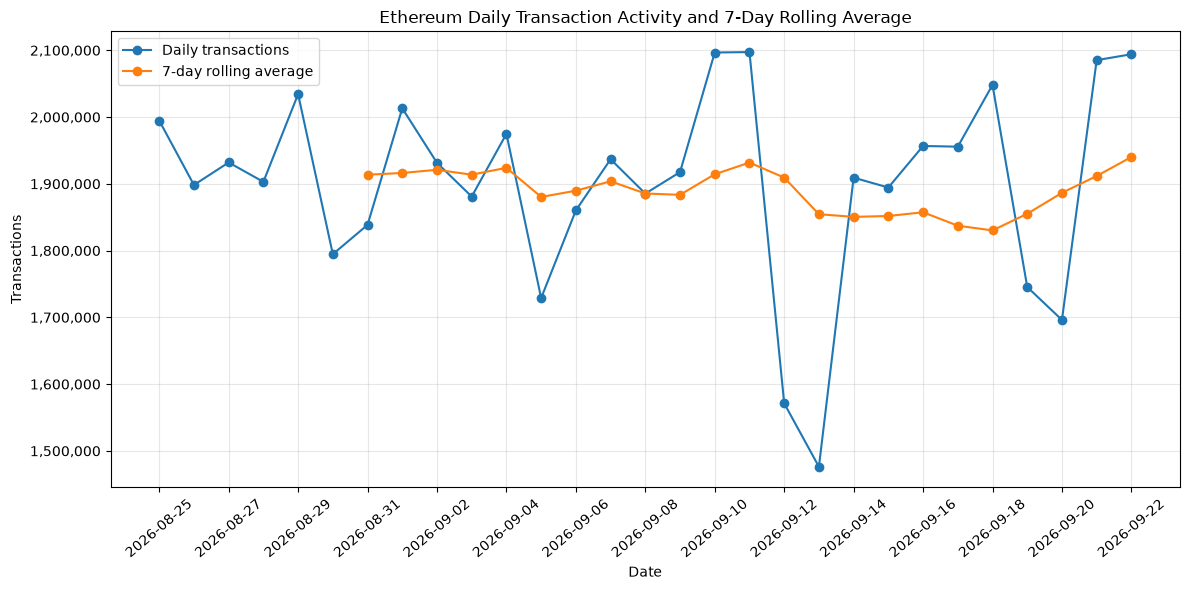

In [105]:
fig, ax = plt.subplots(figsize=(12, 6))

plt.plot(
    complete_days["date"],
    complete_days["transaction_count"],
    marker="o",
    label="Daily transactions"
)

plt.plot(
    complete_days["date"],
    complete_days["rolling_7d"],
    label = "7-day rolling average"
    ,marker="o"
)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Show every 2nd date
ax.set_xticks(complete_days["date"][::2])

plt.title("Ethereum Daily Transaction Activity and 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Transactions")
plt.xticks(rotation=40)
plt.legend()
plt.tight_layout()
plt.grid(alpha=0.3)

## Plotly Visualization


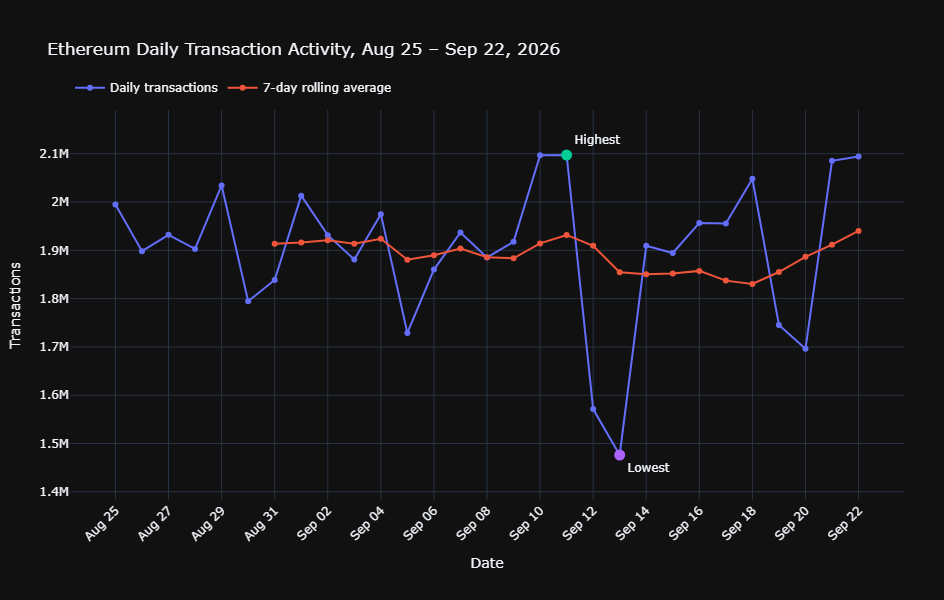

In [106]:
import plotly.express as px


# Prepare data for visualization
plot_df = complete_days[
    ["date", "transaction_count", "rolling_7d"]
].copy()

plot_df = plot_df.rename(
    columns={
        "transaction_count": "Daily transactions",
        "rolling_7d": "7-day rolling average"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="transactions"
)


# Identify highest and lowest activity days
highest_day = complete_days.loc[
    complete_days["transaction_count"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["transaction_count"].idxmin()
]


# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="transactions",
    color="metric",
    title="Ethereum Daily Transaction Activity, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "transactions": "Transactions",
        "metric": ""
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Transactions",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format line markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:,.0f} transactions"
        "<extra></extra>"
    )
)


# Add highest activity marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["transaction_count"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.0f} transactions"
        "<extra></extra>"
    )
)


# Add lowest activity marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["transaction_count"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest activity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:,.0f} transactions"
        "<extra></extra>"
    )
)


# Add padding to the y-axis so annotations are not clipped
y_min = complete_days["transaction_count"].min()
y_max = complete_days["transaction_count"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)


# Display the chart
fig.show()

## 9. Quantify daily variability

Standard deviation measures the absolute dispersion of daily transactions around the mean.

The coefficient of variation (CV) expresses that dispersion relative to the mean, making it easier to interpret the variability in percentage terms.

Interpretation: A lower CV means less variability and higher stability. A higher CV means more variability and lower consistency.

In [107]:
daily_std = complete_days["transaction_count"].std()

daily_cv = (
    daily_std / complete_days["transaction_count"].mean()
) * 100

daily_std, daily_cv

(np.float64(149579.2160261743), np.float64(7.8653052744323935))

## 10. Finding | Evidence | Meaning
### Finding

Ethereum's daily transaction activity was **relatively stable overall** across the 29 complete days in the observation period, despite noticeable day-to-day fluctuations.

### Evidence

- Mean daily transactions: **1,901,759.83**
- Median daily transactions: **1,917,517**
- Standard deviation: **149,579.22**
- Coefficient of variation: **7.87%**
- Highest complete day: **September 11, 2026 — 2,097,342 transactions**
- Lowest complete day: **September 13, 2026 — 1,476,230 transactions**
- Highest day was **42.07%** above the lowest day.
- First-to-last complete-day change: **+4.98%**

### Meaning

The network maintained a broadly consistent level of daily transaction activity during the observation period, while experiencing several short-lived increases and decreases rather than a persistent directional movement.

This interpretation considers the descriptive statistics and observed transaction-count patterns, including the 7-day rolling average. It describes the observed behavior of Ethereum's transaction activity but does not imply a causal explanation for individual spikes or drops.

## Limitations

- The analysis covers a single 30-day period and therefore does not establish longer-term Ethereum activity trends.
- `transaction_count` measures transaction volume, but does not directly represent unique users, economic value transferred, or the complexity of transactions.
- The first and last calendar dates are partial days and were excluded from comparable daily statistics.
- Observed spikes and declines describe changes in network activity but do not establish why those changes occurred.